# 04 · Linear regression: arrival delay from departure delay

**Course topic 2 (linear regression).** `src/clean.py` fills the 292 missing `Arrival Delay in Minutes` with the
same flight's departure delay. Is that a good rule? We fit a linear regression on the rows where both delays are
known and compare it with the "copy departure delay" rule on a held-out 20%.

In [1]:
import sys
sys.path.append('..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from src.clean import load_data

train, _ = load_data()
d = train[['Departure Delay in Minutes', 'Arrival Delay in Minutes']].dropna()
print('rows with both delays:', len(d), ' missing arrival delay:', train['Arrival Delay in Minutes'].isna().sum())
print('correlation:', round(d.corr().iloc[0, 1], 4))
print('share of flights with zero departure delay:', round((d['Departure Delay in Minutes'] == 0).mean(), 3))

rows with both delays: 699343  missing arrival delay: 292
correlation: 0.842
share of flights with zero departure delay: 0.908


## Fit on 80%, test on 20%

In [2]:
X = d[['Departure Delay in Minutes']]
y = d['Arrival Delay in Minutes']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

lin = LinearRegression().fit(X_tr, y_tr)
pred_lin = lin.predict(X_te)
pred_copy = X_te['Departure Delay in Minutes'].to_numpy()     # the rule used in src/clean.py

def scores(pred):
    return {'R²': r2_score(y_te, pred), 'RMSE (min)': mean_squared_error(y_te, pred) ** 0.5,
            'MAE (min)': mean_absolute_error(y_te, pred)}

print(f'arrival delay ≈ {lin.intercept_:.2f} + {lin.coef_[0]:.3f} × departure delay')
table = pd.DataFrame({'linear regression': scores(pred_lin), 'copy departure delay': scores(pred_copy)}).T.round(3)
table

arrival delay ≈ 0.18 + 0.814 × departure delay


,R²,RMSE (min),MAE (min)
linear regression,0.682,3.087,0.950
copy departure delay,0.639,3.289,0.884


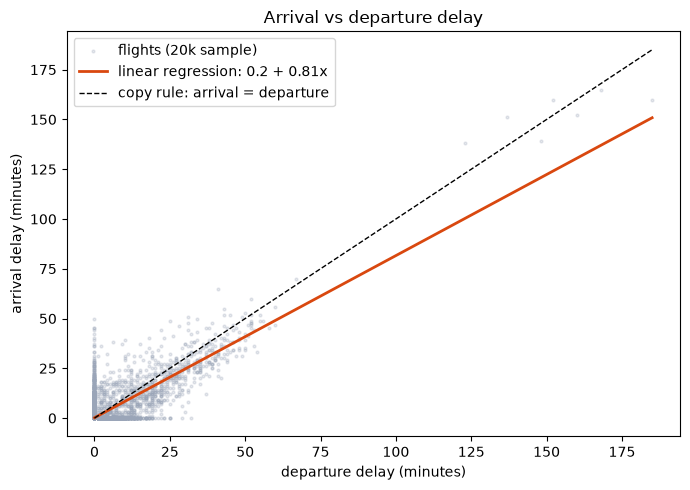

In [3]:
s = d.sample(20_000, random_state=0)
xs = np.linspace(0, s['Departure Delay in Minutes'].max(), 100)
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(s['Departure Delay in Minutes'], s['Arrival Delay in Minutes'], s=4, alpha=0.25, color='#9aa5b8', label='flights (20k sample)')
ax.plot(xs, lin.intercept_ + lin.coef_[0] * xs, color='#d9480f', lw=2,
        label=f'linear regression: {lin.intercept_:.1f} + {lin.coef_[0]:.2f}x')
ax.plot(xs, xs, color='black', ls='--', lw=1, label='copy rule: arrival = departure')
ax.set_xlabel('departure delay (minutes)'); ax.set_ylabel('arrival delay (minutes)')
ax.set_title('Arrival vs departure delay')
ax.legend()
plt.tight_layout(); plt.savefig('../report/figures/linear_regression_delay.png', dpi=150); plt.show()